# Notebook that will align the CdTe data using the optical center, and then use the SPARCS pointing to get a first comparison to AIA

## Step 1: get the FOXSI target data all ready again

In [2]:
from utils.io.cdtetargetdict import CdTeDataParsing

cdte_filelist = [
    '/Users/pet00184/FOXSI_Analysis/FOXSI5_CdTeAnalysis/Data/CdTeFlightData/DRAFT_foxsi5_cdte1_level3_version1.fits',
    '/Users/pet00184/FOXSI_Analysis/FOXSI5_CdTeAnalysis/Data/CdTeFlightData/DRAFT_foxsi5_cdte3_level3_version1.fits',
    '/Users/pet00184/FOXSI_Analysis/FOXSI5_CdTeAnalysis/Data/CdTeFlightData/DRAFT_foxsi5_cdte4_level3_version1.fits',
    '/Users/pet00184/FOXSI_Analysis/FOXSI5_CdTeAnalysis/Data/CdTeFlightData/DRAFT_foxsi5_cdte5_level3_version1.fits'
]

flightdata = CdTeDataParsing(cdte_filelist)

## Step 2: Plot all of the data, aligning their optical centers to CdTe4's optical center

Use the two following plots to check that this alignment makes sense for the targets!

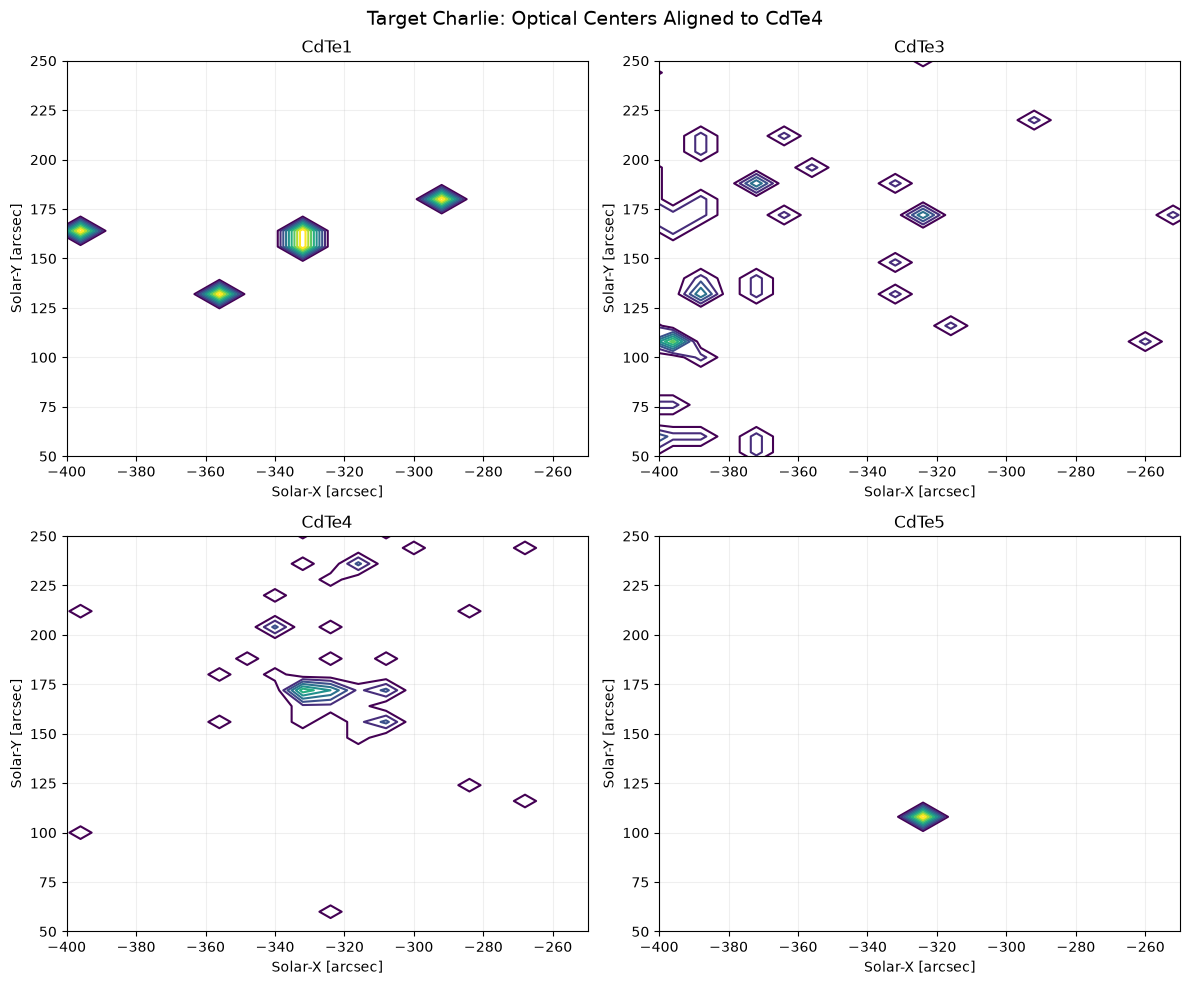

In [98]:
#you can do this for each target, just to get an idea! It may not work with Alpha Pre-Shift since there are no CdTe5 counts (still fixing edge cases)

import importlib
import utils.processing.filtering as filtering
import utils.visualization.coalignfoxsiplotting as cfp
# Reload the modules in dependency order
importlib.reload(filtering)
importlib.reload(cfp)
import matplotlib.pyplot as plt

###### For these, zoom into the specific region and make sure the data looks ok

# 2x2 plot: each detector aligned to CdTe4
fig, axes = cfp.plot_optical_center_aligned(
    cdte_target_dict=flightdata.CDTE_DICT,
    target="Target Charlie",
    bins=250,
    qualityflag=True,
    xlim=(-400, -250),
    ylim=(50, 250)
)

plt.show()

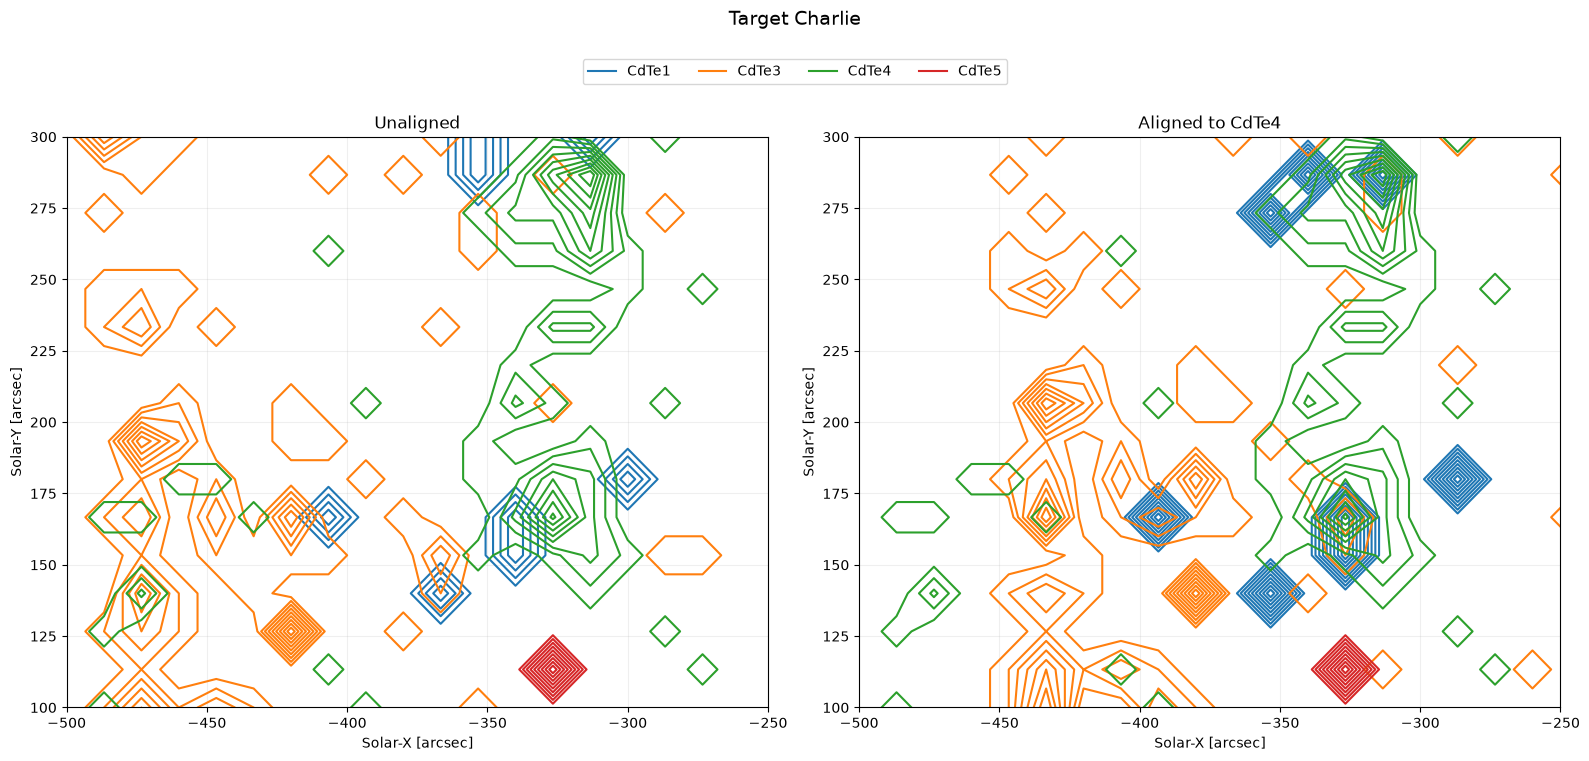

In [100]:
# This shows a side by side comparison of contours before and after aligning them

fig, axes = cfp.plot_optical_center_contour_comparison(
    cdte_target_dict=flightdata.CDTE_DICT,
    target="Target Charlie",
    bins=150,
    qualityflag=True,
    xlim=(-500, -250),
    ylim=(100, 300),
    #contour_fractions=(0.3, 0.5, 0.7, 0.9)
)

plt.show()

## Step 3: Next, lets combine the data and plot it assuming the optical center is at the SPARCS pointing location!

Note: you can specify which detector counts you want to keep. This makes it so that for target Charlie, we can just use CdTe4. 

In [101]:
import importlib

import utils.alignment.opticalcenter as opticalcenter
import utils.processing.filtering as filtering
import utils.visualization.coalignfoxsiplotting as cfp

importlib.reload(opticalcenter)
importlib.reload(filtering)
importlib.reload(cfp)

<module 'utils.visualization.coalignfoxsiplotting' from '/Users/pet00184/FOXSI_Analysis/FOXSI5_CdTeAnalysis/FOXSIOpticalAlignment/utils/visualization/coalignfoxsiplotting.py'>

In [102]:
# make the combined datasets and apply the sparcs correction for each target (not Alpha Pre-shift yet)

targets = [
    "Target Alpha",
    "Target Echo",
    "Target Charlie",
    "Target Alpha 2",
]

for target in targets:

    # First create optical-center-aligned combined data
    filtering.build_combined_cdte_data(
        cdte_target_dict=flightdata.CDTE_DICT,
        target=target,
    )

    # Then create SPARCS-shifted data
    filtering.build_sparcs_shifted_cdte_data(
        cdte_target_dict=flightdata.CDTE_DICT,
        target=target,
    )

You can plot with the SPARCS correction without AIA! Note, you can add a gaussian filter to the contours, and only include specific CdTe. You can also specify an energy range

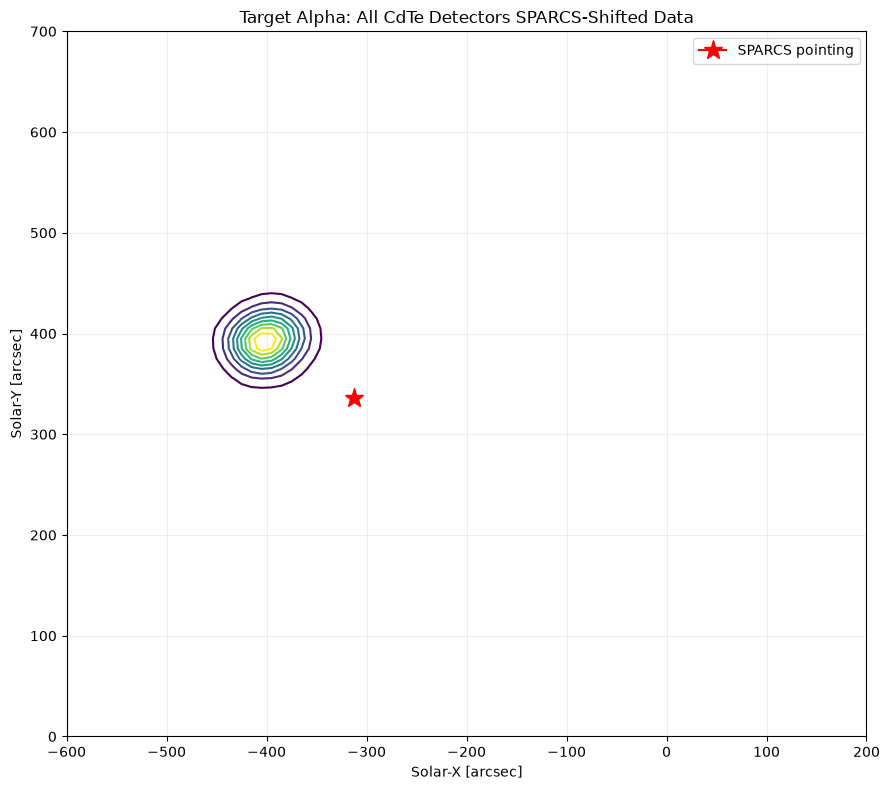

In [103]:
fig, ax = cfp.plot_sparcs_shifted_data(
    cdte_target_dict=flightdata.CDTE_DICT,
    target="Target Alpha",
    bins=200,
    qualityflag=True,
    gaussian_sigma=1.5,
    xlim=(-600, 200),
    ylim=(0, 700),
    specific_cdte=None,
    energy_range=None
)

plt.show()

## Step 4: Plot the SPARCS-aligned data over AIA! 

This takes the AIA iamge closest to the middle of the target observation, and plots the CdTe contours over it (assuming the optical centers are all aligned to the SPARCS location.)

surprise surprise.. this is not good! 

Target Alpha, AIA 94 Å:
Target middle: 2026-05-14T19:26:10.000
AIA frame:    2026-05-14T19:26:11.120
Time offset:  1.1 seconds


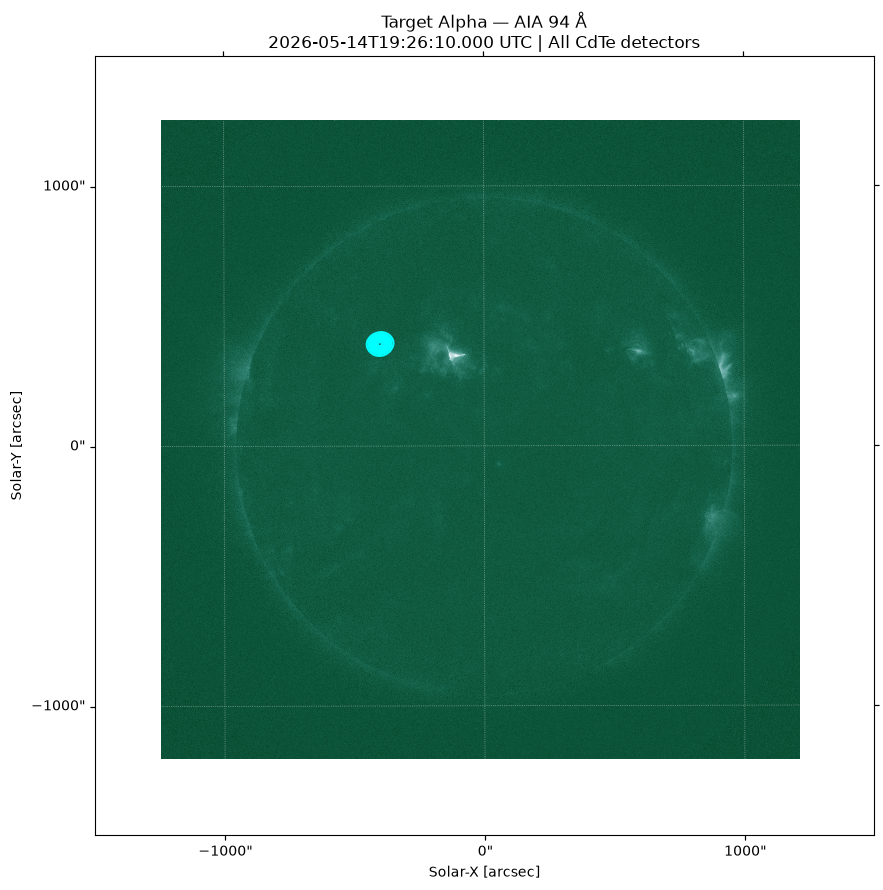

In [ ]:
fig, ax, cdte_map, aia_map = cfp.plot_sparcs_cdte_on_aia(
    cdte_target_dict=flightdata.CDTE_DICT,
    target="Target Alpha",
    aia_wavelength=94,
    bins=300,
    sigma=2,
    qualityflag=True,
    # xlim=(-600, 200),
    # ylim=(0, 700),
    # aia_dir= ## PUT THIS IN TO POINT TO YOUR AIA DATA! if you download with Fido and just dump all wavelengths into a folder it will find the right one for you given the wavelength argument
)

plt.show()